In [129]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [130]:
# load the dataset 
df=pd.read_csv(r"D:\chrome downloads\Bank Customer Churn Prediction.csv")

In [131]:
df.head()

,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [132]:
# find duplicates rows and delete it

df.duplicated().sum()
df.drop_duplicates()

,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...
9995,15606229,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,15569892,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,15584532,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,15682355,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1


In [133]:
df.shape

(10000, 12)

In [134]:
df.size

120000

In [135]:
df.ndim

2

In [136]:
# find data types

df.dtypes

customer_id           int64
credit_score          int64
country                 str
gender                  str
age                   int64
tenure                int64
balance             float64
products_number       int64
credit_card           int64
active_member         int64
estimated_salary    float64
churn                 int64
dtype: object

In [137]:
# find information

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customer_id       10000 non-null  int64  
 1   credit_score      10000 non-null  int64  
 2   country           10000 non-null  str    
 3   gender            10000 non-null  str    
 4   age               10000 non-null  int64  
 5   tenure            10000 non-null  int64  
 6   balance           10000 non-null  float64
 7   products_number   10000 non-null  int64  
 8   credit_card       10000 non-null  int64  
 9   active_member     10000 non-null  int64  
 10  estimated_salary  10000 non-null  float64
 11  churn             10000 non-null  int64  
dtypes: float64(2), int64(8), str(2)
memory usage: 1.0 MB


In [138]:
# find null values in data set
# there is no null values there

df.isna().sum()

customer_id         0
credit_score        0
country             0
gender              0
age                 0
tenure              0
balance             0
products_number     0
credit_card         0
active_member       0
estimated_salary    0
churn               0
dtype: int64

In [139]:
# convert all column name capital letter to small letter
# replace space to underscore

df.columns=df.columns.str.lower()
df.columns=df.columns.str.replace(" ","_")

In [140]:
# make a age group column based on age

labels=["young_adult","adult","middle_age","senior"]
df["age_group"]=pd.qcut(df["age"],q=4,labels=labels)

In [141]:
df.head()

,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn,age_group
0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1,middle_age
1,15647311,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,middle_age
2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,middle_age
3,15701354,699,France,Female,39,1,0.00,2,0,0,93826.63,0,middle_age
4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,middle_age


In [142]:
# change column name tenure to years of service

df.rename(columns={"tenure":"years_of_service"},inplace=True)

In [143]:
df.head(5)

,customer_id,credit_score,country,gender,age,years_of_service,balance,products_number,credit_card,active_member,estimated_salary,churn,age_group
0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1,middle_age
1,15647311,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,middle_age
2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,middle_age
3,15701354,699,France,Female,39,1,0.00,2,0,0,93826.63,0,middle_age
4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,middle_age


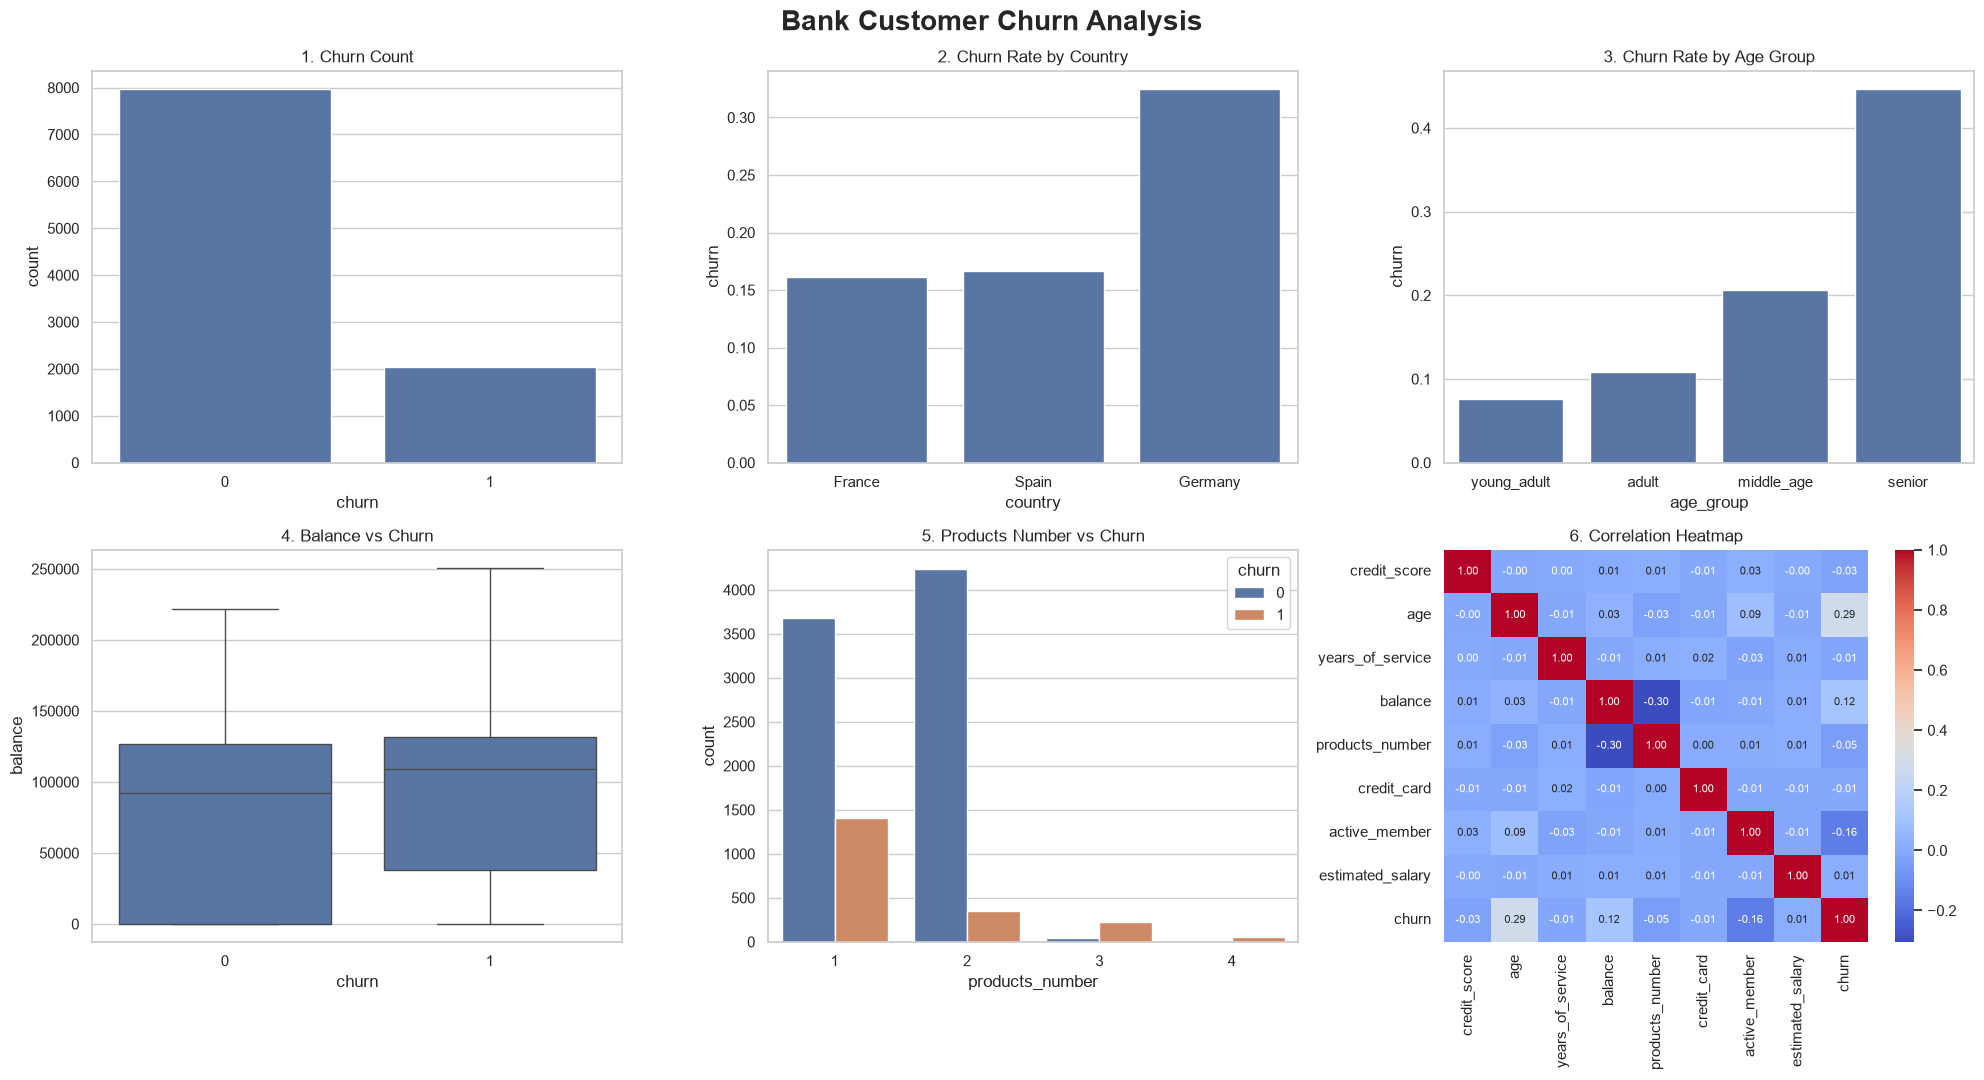

In [144]:
# draw 6 charts based on Overall churn,count Churn rate by country,
# Churn rate by age group,Balance vs churn,Products number vs churn,Correlation heatmap


sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 3, figsize=(20, 11))

# 1. Overall churn count
sns.countplot(data=df, x="churn", ax=axes[0, 0])
axes[0, 0].set_title("1. Churn Count")

# 2. Churn rate by country
sns.barplot(data=df, x="country", y="churn", errorbar=None, ax=axes[0, 1])
axes[0, 1].set_title("2. Churn Rate by Country")

# 3. Churn rate by age group
sns.barplot(data=df, x="age_group", y="churn", errorbar=None, ax=axes[0, 2])
axes[0, 2].set_title("3. Churn Rate by Age Group")

# 4. Balance vs churn
sns.boxplot(data=df, x="churn", y="balance", ax=axes[1, 0])
axes[1, 0].set_title("4. Balance vs Churn")

# 5. Products number vs churn
sns.countplot(data=df, x="products_number", hue="churn", ax=axes[1, 1])
axes[1, 1].set_title("5. Products Number vs Churn")

# 6. Correlation heatmap
corr = df.select_dtypes("number").drop(columns="customer_id").corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm",
            annot_kws={"size": 8}, ax=axes[1, 2])
axes[1, 2].set_title("6. Correlation Heatmap")

plt.suptitle("Bank Customer Churn Analysis", fontsize=20, fontweight="bold")
plt.tight_layout()
plt.show()

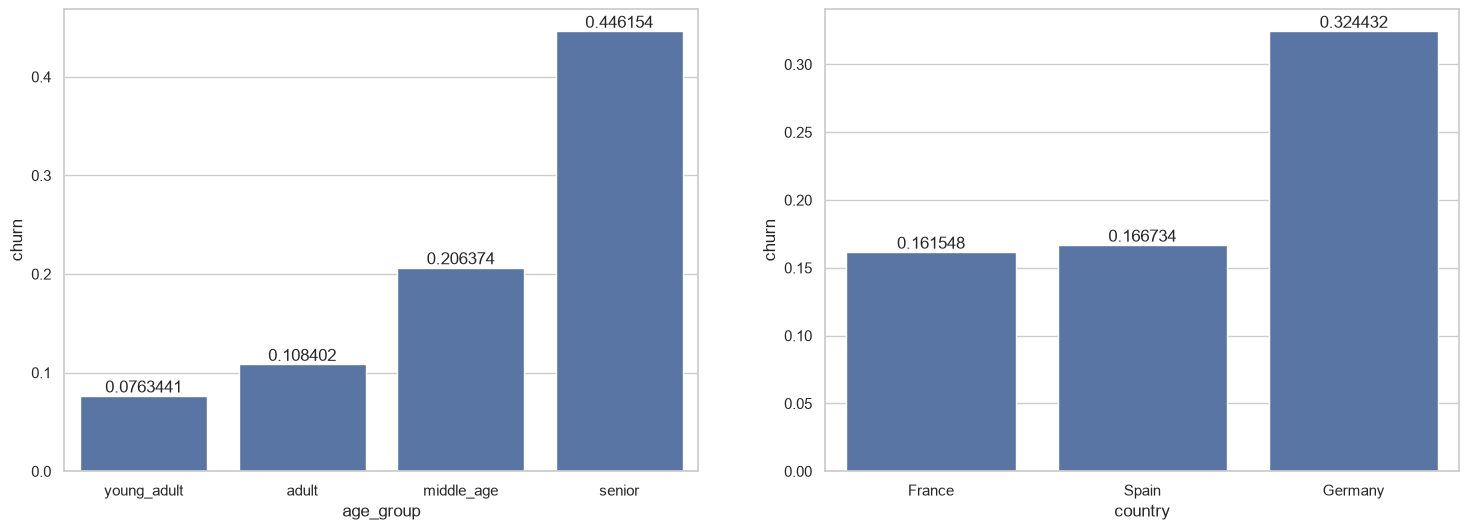

In [145]:
# find count of churn based on country

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(18, 6))


df1=sns.barplot(data=df,x="age_group",y="churn",errorbar=None,ax=axes[0])
for v1 in df1.containers:
    df1.bar_label(v1)

df1=sns.barplot(data=df,x="country",y="churn",errorbar=None, ax=axes[1])
for v1 in df1.containers:
    df1.bar_label(v1)

In [78]:
df.to_csv("bank_churn_analysis.csv",index=False)

In [146]:
n=df.select_dtypes(include="number")
n

,customer_id,credit_score,age,years_of_service,balance,products_number,credit_card,active_member,estimated_salary,churn
0,15634602,619,42,2,0.00,1,1,1,101348.88,1
1,15647311,608,41,1,83807.86,1,0,1,112542.58,0
2,15619304,502,42,8,159660.80,3,1,0,113931.57,1
3,15701354,699,39,1,0.00,2,0,0,93826.63,0
4,15737888,850,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...
9995,15606229,771,39,5,0.00,2,1,0,96270.64,0
9996,15569892,516,35,10,57369.61,1,1,1,101699.77,0
9997,15584532,709,36,7,0.00,1,0,1,42085.58,1
9998,15682355,772,42,3,75075.31,2,1,0,92888.52,1


In [147]:
n.skew()

customer_id         0.001149
credit_score       -0.071607
age                 1.011320
years_of_service    0.010991
balance            -0.141109
products_number     0.745568
credit_card        -0.901812
active_member      -0.060437
estimated_salary    0.002085
churn               1.471611
dtype: float64

In [153]:
df=df.loc[df["churn"]==0]
df.count()

customer_id         0
credit_score        0
country             0
gender              0
age                 0
years_of_service    0
balance             0
products_number     0
credit_card         0
active_member       0
estimated_salary    0
churn               0
age_group           0
dtype: int64